# DATA ANALYTICS AND VISUALIZATION (DAV) PROJECT

## Student Academic Performance Analysis and Prediction Using Machine Learning

**Submitted By:** Nischitha P S
                  (2026LCS024)
                  
**Department:** Computer Science and Engineering

**Academic Year:** 2026–2027
# Introduction

The project titled **Student Academic Performance Analysis and Prediction Using Machine Learning** focuses on analyzing students' academic performance and identifying the factors that influence their examination results.

The project uses Python, Data Analysis and Machine Learning techniques to study student information such as study hours, attendance, previous examination scores, sleep habits and class participation.

Different Machine Learning algorithms are implemented to predict students' final examination scores, classify students into Pass and Fail categories, and group students based on their academic characteristics.

The project includes data cleaning, preprocessing, exploratory data analysis, data visualization, feature engineering and Machine Learning model development.

The main aim of this project is to understand student performance patterns and demonstrate how Machine Learning can support academic performance analysis and prediction.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer

print("All libraries imported successfully!")

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer

print("All libraries imported successfully!")

All libraries imported successfully!


In [50]:
df = pd.read_csv("student_performance_raw.csv")

print("Student Performance Dataset Loaded!")
print("Dataset Shape:", df.shape)

display(df.head())

Student Performance Dataset Loaded!
Dataset Shape: (1015, 19)


,student_id,gender,age,school_type,parental_education,family_income,internet_access,extracurricular,tutoring,study_hours_per_week,attendance_percent,sleep_hours,absences,previous_exam_score,math_score,reading_score,writing_score,final_score,result
0,STU2878,Female,18,Private,Graduate,High,Yes,No,Yes,18.5,66.5,5.6,11,61.9,69.2,75.0,64.0,65.9,Pass
1,STU2877,Female,18,Government,Post Graduate,Medium,Yes,No,No,16.3,70.8,6.9,9,72.9,73.1,81.6,66.7,74.0,Pass
2,STU2358,Female,18,Private,High School,Low,Yes,Yes,No,21.7,83.8,5.6,8,NaN,75.0,79.4,61.1,63.7,Pass
3,STU2176,Female,15,Government,Post Graduate,Medium,Yes,No,Yes,20.0,85.7,6.4,10,72.6,63.7,89.5,72.1,70.8,Pass
4,STU2011,Female,17,Private,Graduate,Low,Yes,Yes,No,11.3,79.0,7.5,13,58.3,47.5,46.4,58.9,54.0,Fail


In [51]:
activity = pd.read_csv("student_activity.csv")

print("Student Activity Dataset Loaded!")
print("Dataset Shape:", activity.shape)

display(activity.head())

Student Activity Dataset Loaded!
Dataset Shape: (1000, 4)


,student_id,library_visits_per_month,online_course_hours,class_participation
0,STU2642,5,6.1,4.8
1,STU2762,4,2.9,7.4
2,STU2909,4,5.9,6.7
3,STU2199,8,9.2,5.0
4,STU2586,3,4.9,5.5


In [52]:
print("Student Performance Columns:")
print(df.columns.tolist())

print("\nStudent Activity Columns:")
print(activity.columns.tolist())

Student Performance Columns:
['student_id', 'gender', 'age', 'school_type', 'parental_education', 'family_income', 'internet_access', 'extracurricular', 'tutoring', 'study_hours_per_week', 'attendance_percent', 'sleep_hours', 'absences', 'previous_exam_score', 'math_score', 'reading_score', 'writing_score', 'final_score', 'result']

Student Activity Columns:
['student_id', 'library_visits_per_month', 'online_course_hours', 'class_participation']


In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1015 entries, 0 to 1014
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            1015 non-null   str    
 1   gender                1015 non-null   str    
 2   age                   1015 non-null   int64  
 3   school_type           1015 non-null   str    
 4   parental_education    1000 non-null   str    
 5   family_income         1003 non-null   str    
 6   internet_access       1015 non-null   str    
 7   extracurricular       1015 non-null   str    
 8   tutoring              1015 non-null   str    
 9   study_hours_per_week  985 non-null    float64
 10  attendance_percent    989 non-null    float64
 11  sleep_hours           995 non-null    float64
 12  absences              1015 non-null   int64  
 13  previous_exam_score   985 non-null    float64
 14  math_score            995 non-null    float64
 15  reading_score         1015 non-n

In [54]:
#statistical information
df.describe()


,age,study_hours_per_week,attendance_percent,sleep_hours,absences,previous_exam_score,math_score,reading_score,writing_score,final_score
count,1015.000000,985.000000,989.000000,995.000000,1015.000000,985.000000,995.000000,1015.000000,1015.000000,1015.000000
mean,16.466995,14.459086,79.289889,7.052563,9.901478,59.704873,58.959698,61.071034,59.584335,58.761970
std,1.026591,6.857679,11.673219,1.224523,6.072877,14.390543,13.773101,12.716977,12.868109,10.735377
min,15.000000,1.000000,38.400000,4.000000,1.000000,15.000000,13.900000,18.700000,17.100000,24.100000
25%,16.000000,10.400000,71.700000,6.200000,7.000000,50.200000,49.600000,52.100000,51.250000,51.800000
50%,16.000000,14.200000,79.600000,7.100000,9.000000,59.500000,58.900000,61.600000,59.700000,58.900000
75%,17.000000,18.100000,87.700000,7.900000,12.000000,69.700000,67.750000,70.400000,68.850000,65.900000
max,18.000000,87.600000,100.000000,10.000000,92.000000,100.000000,148.600000,94.700000,95.900000,89.500000


In [55]:
#activity dataset
activity.info()

activity.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   student_id                1000 non-null   str    
 1   library_visits_per_month  1000 non-null   int64  
 2   online_course_hours       1000 non-null   float64
 3   class_participation       988 non-null    float64
dtypes: float64(2), int64(1), str(1)
memory usage: 38.2 KB


,library_visits_per_month,online_course_hours,class_participation
count,1000.000000,1000.000000,988.000000
mean,5.027000,7.290800,5.960324
std,2.136079,3.169391,1.916077
min,0.000000,0.000000,1.000000
25%,4.000000,5.100000,4.600000
50%,5.000000,7.300000,5.900000
75%,6.000000,9.500000,7.300000
max,14.000000,16.800000,10.000000


In [56]:
# Check missing values in student dataset
print("Missing Values in Student Dataset:")
print(df.isnull().sum())

# Check missing values in activity dataset
print("\nMissing Values in Activity Dataset:")
print(activity.isnull().sum())

Missing Values in Student Dataset:
student_id               0
gender                   0
age                      0
school_type              0
parental_education      15
family_income           12
internet_access          0
extracurricular          0
tutoring                 0
study_hours_per_week    30
attendance_percent      26
sleep_hours             20
absences                 0
previous_exam_score     30
math_score              20
reading_score            0
writing_score            0
final_score              0
result                   0
dtype: int64

Missing Values in Activity Dataset:
student_id                   0
library_visits_per_month     0
online_course_hours          0
class_participation         12
dtype: int64


In [57]:
# Count duplicate records in student dataset
print("Student Dataset Duplicates:", df.duplicated().sum())

# Count duplicate records in activity dataset
print("Activity Dataset Duplicates:", activity.duplicated().sum())

Student Dataset Duplicates: 15
Activity Dataset Duplicates: 0


In [58]:
# Display total rows and columns
print("Student Dataset:", df.shape)
print("Activity Dataset:", activity.shape)

Student Dataset: (1015, 19)
Activity Dataset: (1000, 4)


In [59]:
# Remove duplicate rows from student dataset
df = df.drop_duplicates()

# Remove duplicate rows from activity dataset
activity = activity.drop_duplicates()

# Display remaining duplicate records
print("Student Duplicates:", df.duplicated().sum())
print("Activity Duplicates:", activity.duplicated().sum())

Student Duplicates: 0
Activity Duplicates: 0


In [60]:
# Fill missing numerical values with mean
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].mean())

# Fill missing text values with mode
for col in df.select_dtypes(include=["object", "str"]).columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# Check missing values after cleaning
print("Missing Values After Cleaning:")
print(df.isnull().sum().sum())

Missing Values After Cleaning:
0


In [61]:
# Fill missing numerical values with mean
for col in activity.select_dtypes(include=np.number).columns:
    activity[col] = activity[col].fillna(activity[col].mean())

# Fill missing text values with mode
for col in activity.select_dtypes(include=["object", "str"]).columns:
    if activity[col].isnull().sum() > 0:
        activity[col] = activity[col].fillna(activity[col].mode()[0])

# Check missing values after cleaning
print("Activity Missing Values After Cleaning:")
print(activity.isnull().sum().sum())

Activity Missing Values After Cleaning:
0


In [62]:
# Merge both datasets using student_id
merged_df = pd.merge(df, activity, on="student_id", how="inner")

# Display the first five records
display(merged_df.head())

# Display the dataset size
print("Merged Dataset Shape:", merged_df.shape)


,student_id,gender,age,school_type,parental_education,family_income,internet_access,extracurricular,tutoring,study_hours_per_week,...,absences,previous_exam_score,math_score,reading_score,writing_score,final_score,result,library_visits_per_month,online_course_hours,class_participation
0,STU2878,Female,18,Private,Graduate,High,Yes,No,Yes,18.5,...,11,61.900000,69.2,75.0,64.0,65.9,Pass,6,7.3,4.9
1,STU2877,Female,18,Government,Post Graduate,Medium,Yes,No,No,16.3,...,9,72.900000,73.1,81.6,66.7,74.0,Pass,6,14.3,4.2
2,STU2358,Female,18,Private,High School,Low,Yes,Yes,No,21.7,...,8,59.719588,75.0,79.4,61.1,63.7,Pass,6,5.0,2.5
3,STU2176,Female,15,Government,Post Graduate,Medium,Yes,No,Yes,20.0,...,10,72.600000,63.7,89.5,72.1,70.8,Pass,5,6.0,6.2
4,STU2011,Female,17,Private,Graduate,Low,Yes,Yes,No,11.3,...,13,58.300000,47.5,46.4,58.9,54.0,Fail,4,5.7,3.6


Merged Dataset Shape: (1000, 22)


In [63]:
# Display all merged column names
print("Merged Dataset Columns:")
print(merged_df.columns.tolist())

# Display dataset information
merged_df.info()

Merged Dataset Columns:
['student_id', 'gender', 'age', 'school_type', 'parental_education', 'family_income', 'internet_access', 'extracurricular', 'tutoring', 'study_hours_per_week', 'attendance_percent', 'sleep_hours', 'absences', 'previous_exam_score', 'math_score', 'reading_score', 'writing_score', 'final_score', 'result', 'library_visits_per_month', 'online_course_hours', 'class_participation']
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 22 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   student_id                1000 non-null   str    
 1   gender                    1000 non-null   str    
 2   age                       1000 non-null   int64  
 3   school_type               1000 non-null   str    
 4   parental_education        1000 non-null   str    
 5   family_income             1000 non-null   str    
 6   internet_access           1000 non-null   str    
 7   ex

In [64]:
#------------------------------Exploratory Data Analysis (EDA)----------------------------------------
# Display statistical summary of student data
display(merged_df.describe())

,age,study_hours_per_week,attendance_percent,sleep_hours,absences,previous_exam_score,math_score,reading_score,writing_score,final_score,library_visits_per_month,online_course_hours,class_participation
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,16.469000,14.505052,79.283077,7.049898,9.895000,59.719588,58.996837,61.131000,59.65470,58.805600,5.027000,7.290800,5.960324
std,1.028638,6.786451,11.466309,1.215561,6.105674,14.193161,13.659448,12.726366,12.85899,10.740523,2.136079,3.169391,1.904535
min,15.000000,1.000000,38.400000,4.000000,1.000000,15.000000,13.900000,18.700000,17.10000,24.100000,0.000000,0.000000,1.000000
25%,16.000000,10.500000,72.075000,6.200000,7.000000,50.700000,49.800000,52.250000,51.37500,51.875000,4.000000,5.100000,4.700000
50%,16.000000,14.400000,79.283077,7.074949,9.000000,59.719588,58.996837,61.600000,59.90000,58.900000,5.000000,7.300000,5.900000
75%,17.000000,18.025000,87.400000,7.825000,11.000000,69.225000,67.525000,70.425000,68.92500,65.950000,6.000000,9.500000,7.300000
max,18.000000,87.600000,100.000000,10.000000,92.000000,100.000000,148.600000,94.700000,95.90000,89.500000,14.000000,16.800000,10.000000


In [65]:
# Calculate average final score
print("Average Final Score:", merged_df["final_score"].mean())

Average Final Score: 58.805600000000005


In [66]:
# Find highest and lowest final scores
print("Highest Final Score:", merged_df["final_score"].max())
print("Lowest Final Score:", merged_df["final_score"].min())

Highest Final Score: 89.5
Lowest Final Score: 24.1


In [67]:
# Calculate average weekly study hours
print("Average Study Hours Per Week:",
      merged_df["study_hours_per_week"].mean())

Average Study Hours Per Week: 14.505051546391753


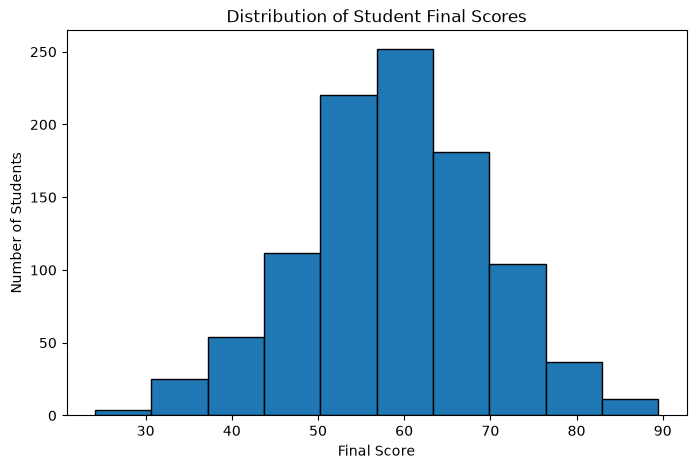

In [68]:
#----------------------------Data Visualization---------------------------
# Display distribution of final scores
plt.figure(figsize=(8, 5))
plt.hist(merged_df["final_score"], bins=10, edgecolor="black")

plt.title("Distribution of Student Final Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Students")

plt.show()

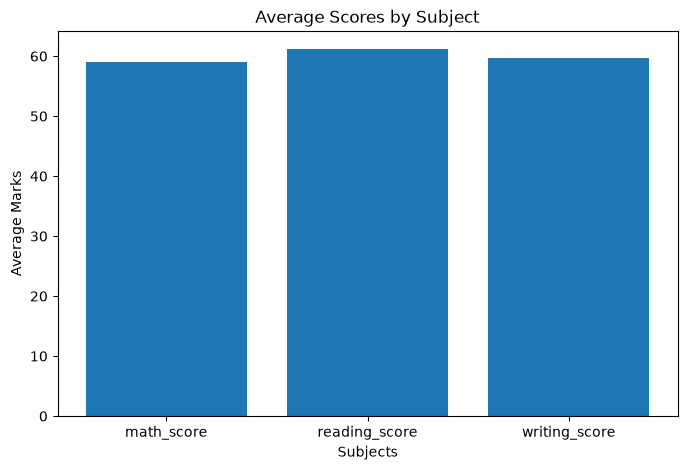

In [69]:
# Calculate average subject scores
subjects = ["math_score", "reading_score", "writing_score"]
averages = merged_df[subjects].mean()

# Display average scores
plt.figure(figsize=(8, 5))
plt.bar(averages.index, averages.values)

plt.title("Average Scores by Subject")
plt.xlabel("Subjects")
plt.ylabel("Average Marks")

plt.show()

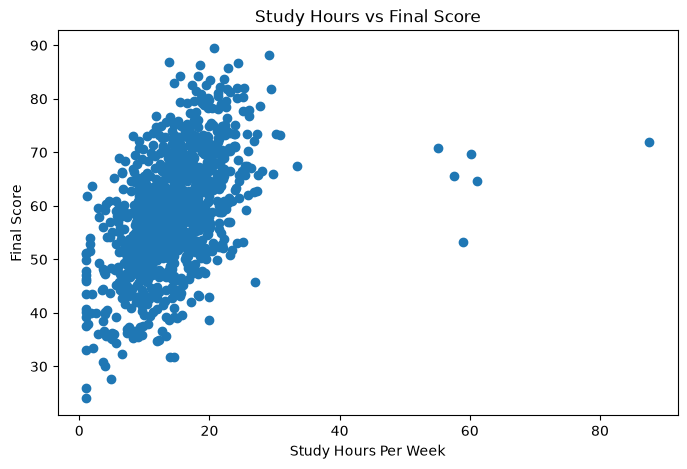

In [70]:
# Compare study hours with final scores
plt.figure(figsize=(8, 5))

plt.scatter(merged_df["study_hours_per_week"],
            merged_df["final_score"])

plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours Per Week")
plt.ylabel("Final Score")

plt.show()

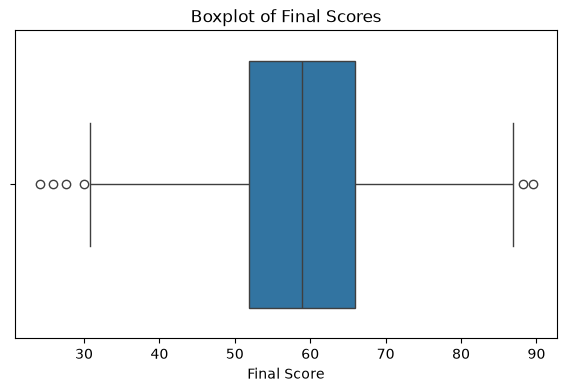

In [71]:
# Display final score distribution
plt.figure(figsize=(7, 4))

sns.boxplot(x=merged_df["final_score"])

plt.title("Boxplot of Final Scores")
plt.xlabel("Final Score")

plt.show()

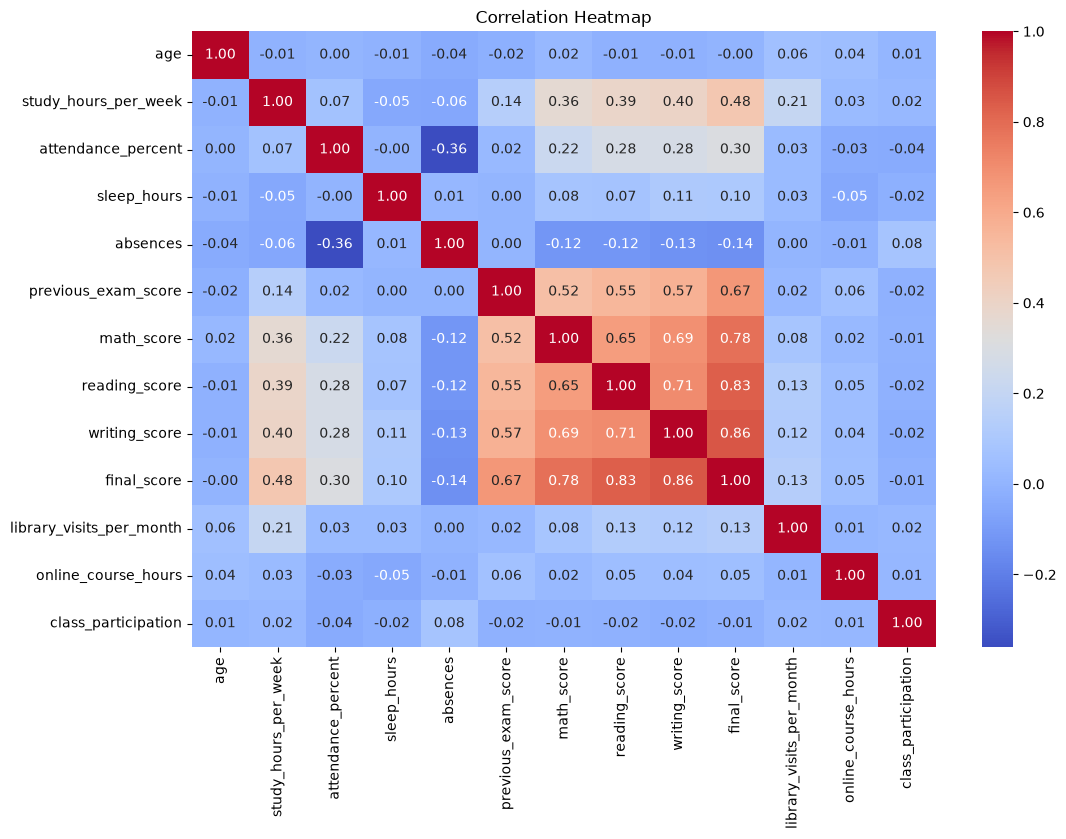

In [72]:
# Select numerical columns
numeric_data = merged_df.select_dtypes(include=np.number)

# Calculate correlation
correlation = numeric_data.corr()

# Display heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

In [73]:
#-------------------Data Preprocessing------------------------
# Create a copy for preprocessing
encoded_df = merged_df.copy()

# Display text columns
print("Categorical Columns:")
print(encoded_df.select_dtypes(include=["object", "str"]).columns.tolist())

Categorical Columns:
['student_id', 'gender', 'school_type', 'parental_education', 'family_income', 'internet_access', 'extracurricular', 'tutoring', 'result']


In [74]:
# Create a label encoder
le = LabelEncoder()

# Convert text columns into numerical values
for col in encoded_df.select_dtypes(include=["object", "str"]).columns:
    if col != "student_id":
        encoded_df[col] = le.fit_transform(encoded_df[col].astype(str))

# Display encoded dataset
display(encoded_df.head())

,student_id,gender,age,school_type,parental_education,family_income,internet_access,extracurricular,tutoring,study_hours_per_week,...,absences,previous_exam_score,math_score,reading_score,writing_score,final_score,result,library_visits_per_month,online_course_hours,class_participation
0,STU2878,0,18,1,0,0,1,0,1,18.5,...,11,61.900000,69.2,75.0,64.0,65.9,1,6,7.3,4.9
1,STU2877,0,18,0,2,2,1,0,0,16.3,...,9,72.900000,73.1,81.6,66.7,74.0,1,6,14.3,4.2
2,STU2358,0,18,1,1,1,1,1,0,21.7,...,8,59.719588,75.0,79.4,61.1,63.7,1,6,5.0,2.5
3,STU2176,0,15,0,2,2,1,0,1,20.0,...,10,72.600000,63.7,89.5,72.1,70.8,1,5,6.0,6.2
4,STU2011,0,17,1,0,1,1,1,0,11.3,...,13,58.300000,47.5,46.4,58.9,54.0,0,4,5.7,3.6


In [75]:
# Display data types after encoding
print(encoded_df.dtypes)

# Check for missing values
print("\nMissing Values:", encoded_df.isnull().sum().sum())

student_id                      str
gender                        int64
age                           int64
school_type                   int64
parental_education            int64
family_income                 int64
internet_access               int64
extracurricular               int64
tutoring                      int64
study_hours_per_week        float64
attendance_percent          float64
sleep_hours                 float64
absences                      int64
previous_exam_score         float64
math_score                  float64
reading_score               float64
writing_score               float64
final_score                 float64
result                        int64
library_visits_per_month      int64
online_course_hours         float64
class_participation         float64
dtype: object

Missing Values: 0


In [76]:
#----------------------Feature Selection and Train-Test Split-----------------------
# Select input features
X = encoded_df.drop(columns=["student_id", "final_score", "result"])

# Select target variable
y = encoded_df["final_score"]

# Display input and output shapes
print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (1000, 19)
Target Shape: (1000,)


In [77]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display the number of records
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 800
Testing Records: 200


In [78]:
#Detect outliers using IQR
# Select numerical columns
numeric_data = merged_df.select_dtypes(include=np.number)

# Calculate first and third quartiles
Q1 = numeric_data.quantile(0.25)
Q3 = numeric_data.quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Find outliers
outliers = ((numeric_data < (Q1 - 1.5 * IQR)) |
            (numeric_data > (Q3 + 1.5 * IQR)))

# Count outliers in each column
print("Outliers using IQR:")
print(outliers.sum())

Outliers using IQR:
age                          0
study_hours_per_week        11
attendance_percent           7
sleep_hours                  0
absences                    12
previous_exam_score          9
math_score                   5
reading_score                1
writing_score                5
final_score                  6
library_visits_per_month    31
online_course_hours          5
class_participation          0
dtype: int64


In [79]:
#Detect outliers using Z-score
# Calculate Z-score
z_scores = (numeric_data - numeric_data.mean()) / numeric_data.std()

# Identify outliers where Z-score is greater than 3 or less than -3
z_outliers = (z_scores > 3) | (z_scores < -3)

# Count outliers in each column
print("Outliers using Z-score:")
print(z_outliers.sum())

Outliers using Z-score:
age                         0
study_hours_per_week        6
attendance_percent          2
sleep_hours                 0
absences                    5
previous_exam_score         2
math_score                  5
reading_score               1
writing_score               1
final_score                 2
library_visits_per_month    6
online_course_hours         1
class_participation         0
dtype: int64


In [80]:
#-----------------------Feature Engineering and PCA---------------------
# Create Min-Max Scaler
minmax = MinMaxScaler()

# Normalize input features
X_normalized = minmax.fit_transform(X)

# Display normalized data
print("Normalized Data:")
display(pd.DataFrame(X_normalized, columns=X.columns).head())

Normalized Data:


,gender,age,school_type,parental_education,family_income,internet_access,extracurricular,tutoring,study_hours_per_week,attendance_percent,sleep_hours,absences,previous_exam_score,math_score,reading_score,writing_score,library_visits_per_month,online_course_hours,class_participation
0,0.0,1.000000,1.0,0.0,0.0,1.0,0.0,1.0,0.202079,0.456169,0.266667,0.109890,0.551765,0.410542,0.740789,0.595178,0.428571,0.434524,0.433333
1,0.0,1.000000,0.0,1.0,1.0,1.0,0.0,0.0,0.176674,0.525974,0.483333,0.087912,0.681176,0.439495,0.827632,0.629442,0.428571,0.851190,0.355556
2,0.0,1.000000,1.0,0.5,0.5,1.0,1.0,0.0,0.239030,0.737013,0.266667,0.076923,0.526113,0.453601,0.798684,0.558376,0.428571,0.297619,0.166667
3,0.0,0.000000,0.0,1.0,1.0,1.0,0.0,1.0,0.219400,0.767857,0.400000,0.098901,0.677647,0.369710,0.931579,0.697970,0.357143,0.357143,0.577778
4,0.0,0.666667,1.0,0.0,0.5,1.0,1.0,0.0,0.118938,0.659091,0.583333,0.131868,0.509412,0.249443,0.364474,0.530457,0.285714,0.339286,0.288889


In [81]:
#Standardization
# Create Standard Scaler
scaler = StandardScaler()

# Standardize input features
X_standardized = scaler.fit_transform(X)

# Display standardized data
print("Standardized Data:")
display(pd.DataFrame(X_standardized, columns=X.columns).head())

Standardized Data:


,gender,age,school_type,parental_education,family_income,internet_access,extracurricular,tutoring,study_hours_per_week,attendance_percent,sleep_hours,absences,previous_exam_score,math_score,reading_score,writing_score,library_visits_per_month,online_course_hours,class_participation
0,-0.968496,1.489120,1.179976,-1.092304,-1.660505,0.541905,-0.984126,1.424887,0.588960,-1.115396,-1.193378,0.181070,0.153701,0.747341,1.090330,0.338088,0.455735,0.002904,-0.557015
1,-0.968496,1.489120,-0.847475,1.748539,1.077344,0.541905,-0.984126,-0.701810,0.264622,-0.740196,-0.123378,-0.146658,0.929110,1.033001,1.609198,0.548163,0.455735,2.212635,-0.924743
2,-0.968496,1.489120,1.179976,0.328117,-0.291581,0.541905,1.016130,-0.701810,1.060724,0.394127,-1.193378,-0.310522,0.000000,1.172168,1.436242,0.112452,0.455735,-0.723150,-1.817796
3,-0.968496,-1.428816,-0.847475,1.748539,1.077344,0.541905,-0.984126,1.424887,0.810099,0.559913,-0.534916,0.017206,0.907962,0.344488,2.230267,0.968313,-0.012646,-0.407474,0.125908
4,-0.968496,0.516475,1.179976,-1.092304,-0.291581,0.541905,1.016130,-0.701810,-0.472508,-0.024700,0.370469,0.508798,-0.100069,-0.842098,-1.158097,-0.058720,-0.481028,-0.502177,-1.239938


In [82]:
#Principal Component Analysis (PCA)
# Import PCA
from sklearn.decomposition import PCA

# Apply PCA and reduce features to 2 components
pca = PCA(n_components=2)

# Transform standardized data
X_pca = pca.fit_transform(X_standardized)

# Display PCA results
pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])

display(pca_df.head())

# Display explained variance
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Explained Variance:",
      pca.explained_variance_ratio_.sum())

,PC1,PC2
0,1.185973,0.941634
1,2.138133,1.503113
2,1.693407,-0.443282
3,2.625628,-0.116992
4,-1.323328,0.146765


Explained Variance Ratio: [0.17091964 0.07276991]
Total Explained Variance: 0.24368955335597095


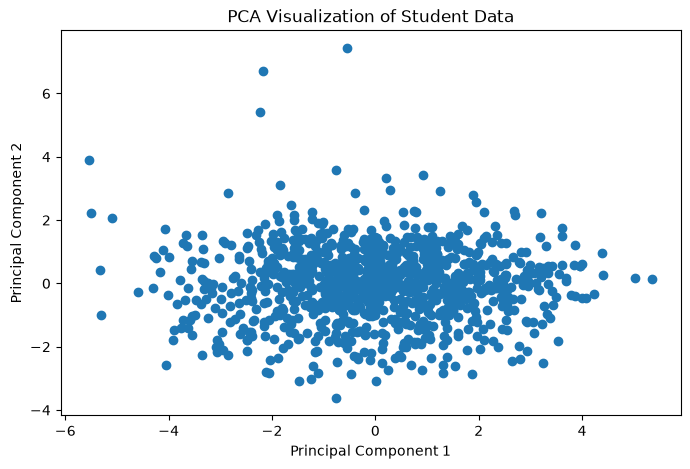

In [83]:
#Visualize PCA results
# Plot the two principal components
plt.figure(figsize=(8, 5))

plt.scatter(pca_df["PC1"], pca_df["PC2"])

plt.title("PCA Visualization of Student Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

In [85]:
#Linear Regression
# Import Linear Regression
from sklearn.linear_model import LinearRegression

# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [86]:
# Create Linear Regression model
lr_model = LinearRegression()

# Train the model using training data
lr_model.fit(X_train, y_train)

# Predict final scores
y_pred = lr_model.predict(X_test)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [87]:
# Calculate model performance
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display evaluation results
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

Mean Absolute Error: 2.713360941140651
Mean Squared Error: 11.797804892415398
Root Mean Squared Error: 3.434793282341078
R2 Score: 0.8908371351447292


In [88]:
# Compare actual and predicted scores
comparison = pd.DataFrame({
    "Actual Marks": y_test.values,
    "Predicted Marks": y_pred
})

# Display first 10 predictions
display(comparison.head(10))

,Actual Marks,Predicted Marks
0,52.1,52.509277
1,58.0,52.513658
2,50.3,47.579488
3,35.6,35.463034
4,52.1,50.398736
5,46.3,49.047749
6,62.3,65.842889
7,56.2,54.835246
8,42.2,46.876941
9,53.3,50.940689


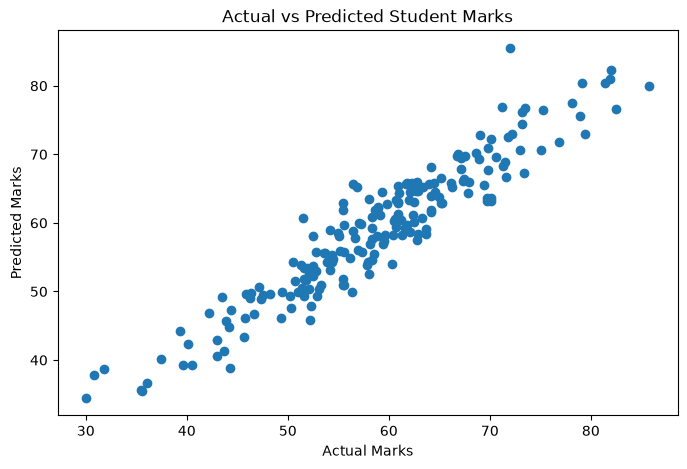

In [89]:
# Plot actual and predicted marks
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Student Marks")

plt.show()

In [90]:
#-----------------Logistic Regression--------------------
# Select input features
X_class = encoded_df.drop(columns=["student_id", "final_score", "result"])

# Select pass/fail result as target
y_class = encoded_df["result"]

# Display pass/fail categories
print("Result Categories:")
print(y_class.value_counts())

Result Categories:
result
1    646
0    354
Name: count, dtype: int64


In [91]:
# Display original result categories
print(merged_df["result"].value_counts())

result
Pass    646
Fail    354
Name: count, dtype: int64


In [92]:
# Split data into training and testing sets
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

# Display dataset sizes
print("Training Records:", len(X_train_class))
print("Testing Records:", len(X_test_class))

Training Records: 800
Testing Records: 200


In [93]:
# Import required libraries
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Scale the input features
class_scaler = StandardScaler()

X_train_scaled = class_scaler.fit_transform(X_train_class)
X_test_scaled = class_scaler.transform(X_test_class)

# Create the Logistic Regression model
log_model = LogisticRegression(max_iter=1000)

# Train the model
log_model.fit(X_train_scaled, y_train_class)

# Predict student results
y_class_pred = log_model.predict(X_test_scaled)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [94]:
# Calculate prediction accuracy
accuracy = accuracy_score(y_test_class, y_class_pred)

# Display accuracy
print("Logistic Regression Accuracy:", accuracy * 100, "%")

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_class, y_class_pred))

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test_class, y_class_pred))

Logistic Regression Accuracy: 89.0 %

Confusion Matrix:
[[ 61  10]
 [ 12 117]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.86      0.85        71
           1       0.92      0.91      0.91       129

    accuracy                           0.89       200
   macro avg       0.88      0.88      0.88       200
weighted avg       0.89      0.89      0.89       200



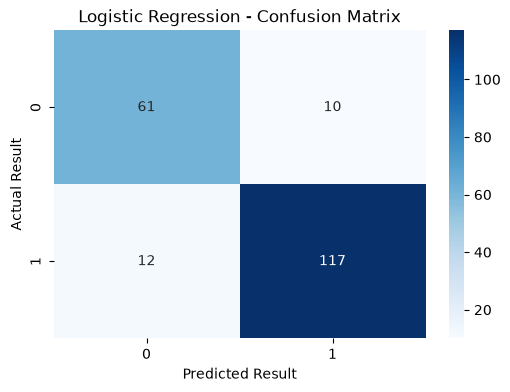

In [95]:
# Create confusion matrix
cm = confusion_matrix(y_test_class, y_class_pred)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

In [96]:
#----------------Decision Tree Classification------------------
# Import Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

# Import evaluation metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Decision Tree libraries imported successfully!")

Decision Tree libraries imported successfully!


In [97]:
# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

# Train the model
dt_model.fit(X_train_class, y_train_class)

# Predict student results
y_dt_pred = dt_model.predict(X_test_class)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [98]:
# Calculate model accuracy
dt_accuracy = accuracy_score(y_test_class, y_dt_pred)

# Display accuracy
print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_class, y_dt_pred))

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test_class, y_dt_pred))

Decision Tree Accuracy: 88.5 %

Confusion Matrix:
[[ 57  14]
 [  9 120]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.80      0.83        71
           1       0.90      0.93      0.91       129

    accuracy                           0.89       200
   macro avg       0.88      0.87      0.87       200
weighted avg       0.88      0.89      0.88       200



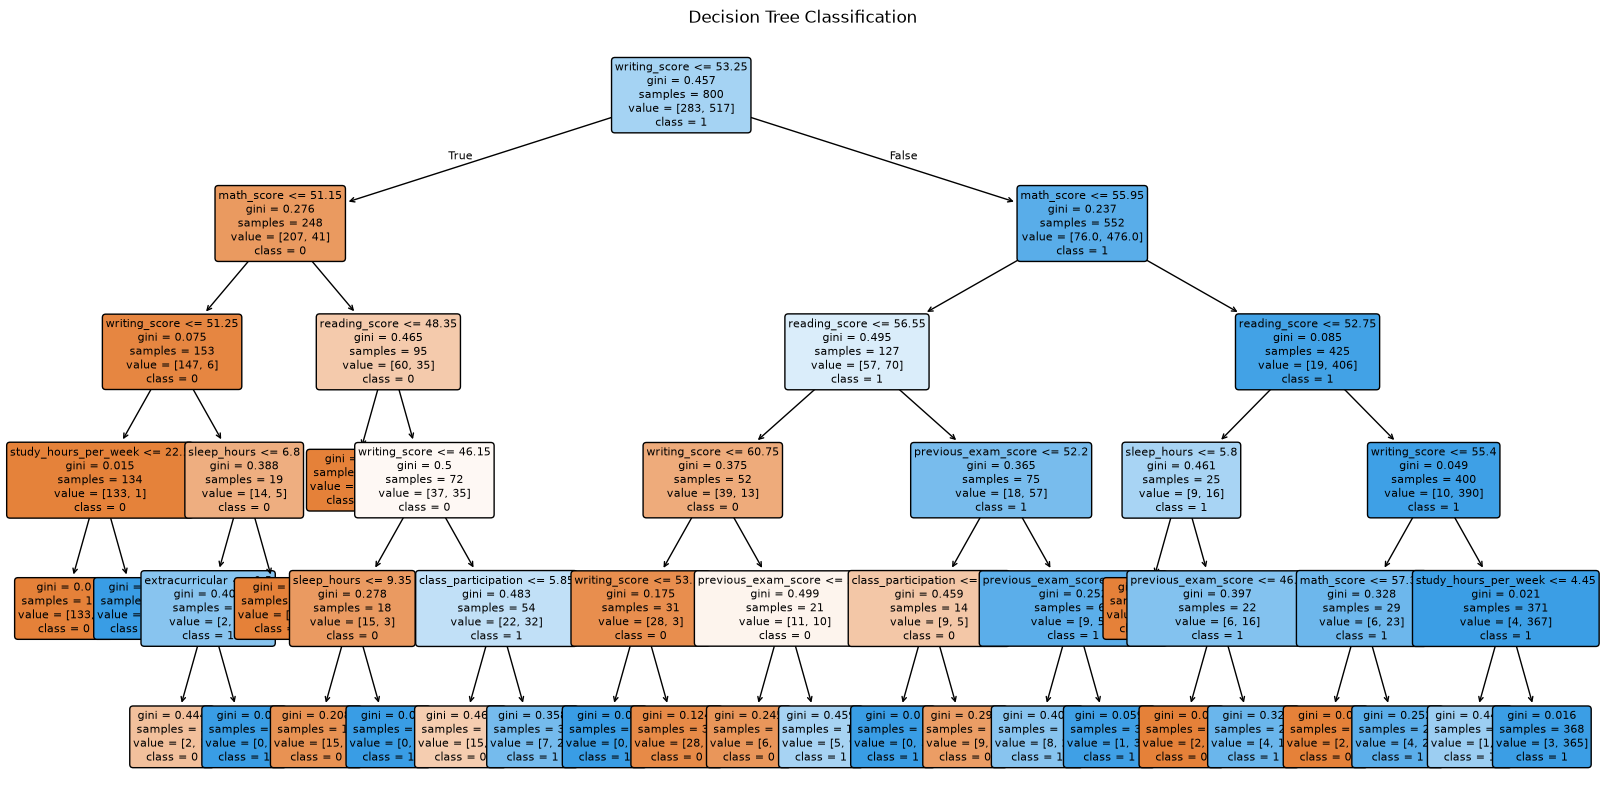

In [99]:
from sklearn.tree import plot_tree

# Set figure size
plt.figure(figsize=(20, 10))

# Visualize decision tree
plot_tree(
    dt_model,
    filled=True,
    feature_names=X_class.columns,
    class_names=["0", "1"],
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classification")
plt.show()

,Model,Accuracy
0,Logistic Regression,89.0
1,Decision Tree,88.5


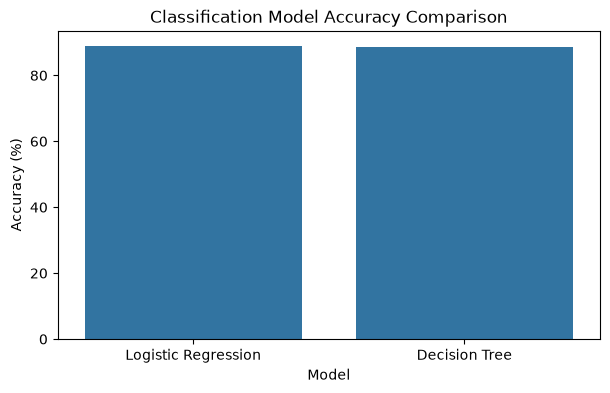

In [100]:
# Compare model accuracy
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [89.0, 88.5]
})

display(model_comparison)

# Visualize comparison
plt.figure(figsize=(7, 4))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Classification Model Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.show()

In [102]:
# Import K-Means clustering
from sklearn.cluster import KMeans

print("K-Means library imported successfully!")

K-Means library imported successfully!


In [103]:
# Display the standardized data shape
print("Standardized Data Shape:", X_standardized.shape)

# Display first 5 records
print(X_standardized[:5])

Standardized Data Shape: (1000, 19)
[[-0.968496    1.48911996  1.17997648 -1.0923042  -1.66050534  0.54190503
  -0.98412598  1.42488702  0.58895986 -1.11539581 -1.19337814  0.18106976
   0.15370103  0.74734123  1.09033012  0.33808831  0.45573541  0.00290422
  -0.55701506]
 [-0.968496    1.48911996 -0.84747452  1.74853897  1.07734353  0.54190503
  -0.98412598 -0.70181003  0.26462234 -0.74019647 -0.12337761 -0.14665831
   0.92910999  1.03300076  1.60919802  0.5481632   0.45573541  2.21263544
  -0.92474284]
 [-0.968496    1.48911996  1.17997648  0.32811739 -0.2915809   0.54190503
   1.01613007 -0.70181003  1.06072354  0.3941271  -1.19337814 -0.31052235
   0.          1.17216822  1.43624205  0.11245231  0.45573541 -0.72315033
  -1.81779601]
 [-0.968496   -1.42881595 -0.84747452  1.74853897  1.07734353  0.54190503
  -0.98412598  1.42488702  0.81009909  0.55991286 -0.53491628  0.01720572
   0.90796247  0.34448805  2.23026716  0.96831299 -0.01264631 -0.40747444
   0.12590795]
 [-0.968496    0

In [105]:
# Create K-Means model with 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train the model and assign clusters
clusters = kmeans.fit_predict(X_standardized)

# Add cluster numbers to the dataset
merged_df["Cluster"] = clusters

print("K-Means Clustering Completed Successfully!")

# Display number of students in each cluster
print("\nStudents in Each Cluster:")
print(merged_df["Cluster"].value_counts().sort_index())

K-Means Clustering Completed Successfully!

Students in Each Cluster:
Cluster
0    402
1    200
2    398
Name: count, dtype: int64


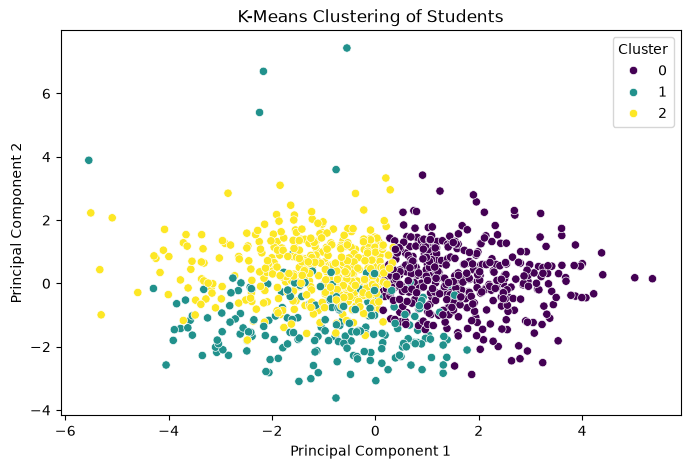

In [106]:
# Visualize student clusters
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=clusters,
    palette="viridis"
)

plt.title("K-Means Clustering of Students")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")

plt.show()

In [107]:
# Calculate average academic performance in each cluster
cluster_analysis = merged_df.groupby("Cluster")[
    [
        "study_hours_per_week",
        "attendance_percent",
        "previous_exam_score",
        "final_score",
        "sleep_hours",
        "class_participation"
    ]
].mean()

# Display cluster analysis
display(cluster_analysis.round(2))

,study_hours_per_week,attendance_percent,previous_exam_score,final_score,sleep_hours,class_participation
Cluster,,,,,,
0,17.74,83.09,68.54,68.13,7.18,5.85
1,13.12,77.56,56.60,54.22,6.99,6.04
2,11.94,76.30,52.38,51.69,6.95,6.03


In [108]:
# Import Hierarchical Clustering
from sklearn.cluster import AgglomerativeClustering

# Import dendrogram functions
from scipy.cluster.hierarchy import linkage, dendrogram

print("Hierarchical Clustering libraries imported successfully!")

Hierarchical Clustering libraries imported successfully!


In [109]:
# Check the standardized dataset
print("Dataset Shape:", X_standardized.shape)

# Display first 5 student records
print("\nFirst 5 Records:")
print(X_standardized[:5])

Dataset Shape: (1000, 19)

First 5 Records:
[[-0.968496    1.48911996  1.17997648 -1.0923042  -1.66050534  0.54190503
  -0.98412598  1.42488702  0.58895986 -1.11539581 -1.19337814  0.18106976
   0.15370103  0.74734123  1.09033012  0.33808831  0.45573541  0.00290422
  -0.55701506]
 [-0.968496    1.48911996 -0.84747452  1.74853897  1.07734353  0.54190503
  -0.98412598 -0.70181003  0.26462234 -0.74019647 -0.12337761 -0.14665831
   0.92910999  1.03300076  1.60919802  0.5481632   0.45573541  2.21263544
  -0.92474284]
 [-0.968496    1.48911996  1.17997648  0.32811739 -0.2915809   0.54190503
   1.01613007 -0.70181003  1.06072354  0.3941271  -1.19337814 -0.31052235
   0.          1.17216822  1.43624205  0.11245231  0.45573541 -0.72315033
  -1.81779601]
 [-0.968496   -1.42881595 -0.84747452  1.74853897  1.07734353  0.54190503
  -0.98412598  1.42488702  0.81009909  0.55991286 -0.53491628  0.01720572
   0.90796247  0.34448805  2.23026716  0.96831299 -0.01264631 -0.40747444
   0.12590795]
 [-0.968

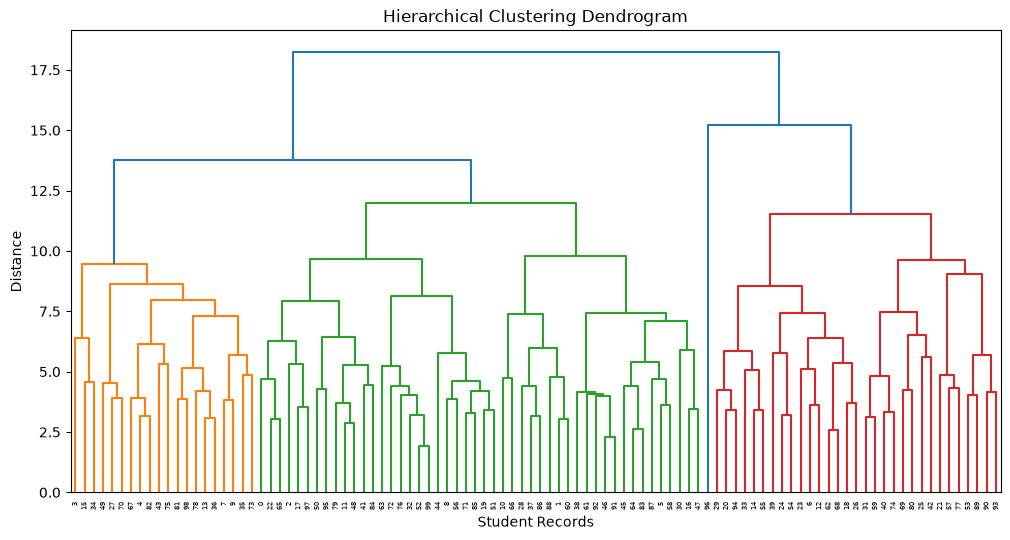

In [110]:
# Select 100 random student records
np.random.seed(42)

sample_indices = np.random.choice(
    X_standardized.shape[0],
    100,
    replace=False
)

sample_data = X_standardized[sample_indices]

# Perform hierarchical linkage
linked = linkage(sample_data, method="ward")

# Draw dendrogram
plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Student Records")
plt.ylabel("Distance")

plt.show()

In [111]:
# Create Hierarchical Clustering model
hc_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

# Assign students to clusters
hc_clusters = hc_model.fit_predict(X_standardized)

# Add cluster numbers to dataset
merged_df["HC_Cluster"] = hc_clusters

print("Hierarchical Clustering Completed Successfully!")

# Count students in each cluster
print("\nStudents in Each Cluster:")
print(merged_df["HC_Cluster"].value_counts().sort_index())

Hierarchical Clustering Completed Successfully!

Students in Each Cluster:
HC_Cluster
0    428
1    567
2      5
Name: count, dtype: int64


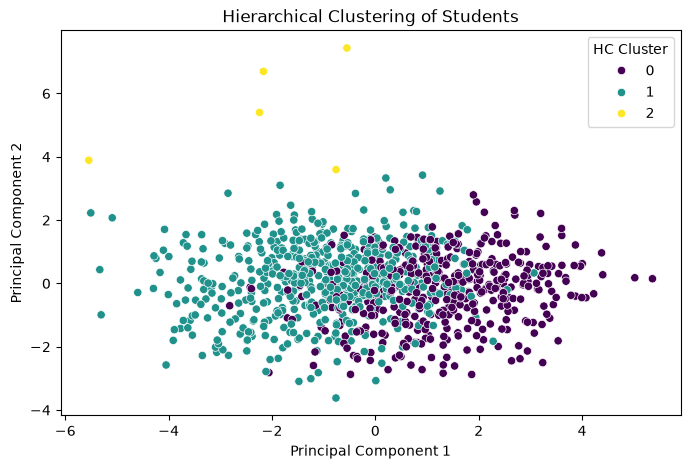

In [112]:
# Visualize Hierarchical Clusters
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=hc_clusters,
    palette="viridis"
)

plt.title("Hierarchical Clustering of Students")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="HC Cluster")

plt.show()

In [113]:
# Analyze average values in each cluster
hc_analysis = merged_df.groupby("HC_Cluster")[
    [
        "study_hours_per_week",
        "attendance_percent",
        "previous_exam_score",
        "final_score",
        "sleep_hours",
        "class_participation"
    ]
].mean()

# Display results
display(hc_analysis.round(2))

,study_hours_per_week,attendance_percent,previous_exam_score,final_score,sleep_hours,class_participation
HC_Cluster,,,,,,
0,17.06,82.58,67.03,66.33,7.15,5.99
1,12.60,76.88,54.23,53.16,6.97,5.93
2,12.06,69.48,56.26,55.00,7.66,7.08


,Algorithm,Accuracy (%)
0,Logistic Regression,89.0
1,Decision Tree,88.5


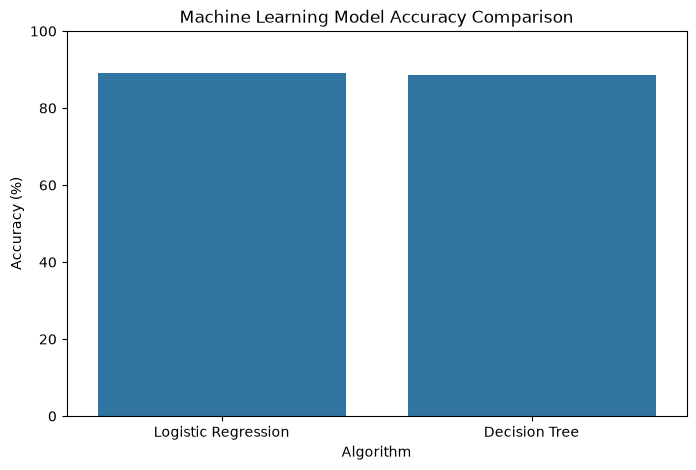

In [114]:
# Compare classification models
model_comparison = pd.DataFrame({
    "Algorithm": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy (%)": [
        89.0,
        88.5
    ]
})

display(model_comparison)

# Visualize model comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Algorithm",
    y="Accuracy (%)"
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.ylim(0, 100)
plt.show()

# Conclusion

The Student Academic Performance Analysis and Prediction project was successfully completed using Python and Jupyter Notebook.

All experiments were performed, including data cleaning, preprocessing, data analysis, visualization and Machine Learning algorithms.

The Linear Regression model achieved an R² score of **89.08%**, Logistic Regression achieved **89% accuracy**, and Decision Tree achieved **88.5% accuracy**. K-Means and Hierarchical Clustering successfully grouped 1,000 student records into three clusters each.

Overall, this project helped us understand student academic performance, predict examination results and identify patterns using Data Analytics, Visualization and Machine Learning techniques.